# 14 · Checkpoint: a browser agent that reproduces a bug
Level L2 · Part 2 · core · ~90 min · builds on 12

## Goal
By the end you have built a **bug-reproducing agent**: a real model reads Pocket Tracker's issue #7, follows its steps in the running app, and files a short verdict. The harness saves **evidence** for every step (an aria snapshot and a screenshot), checks the model's verdict against that evidence and the database, and turns the run into **repro steps** that reproduce the bug again with no model at all.

## The idea
Lesson 12's agent stumbled on seeded bug #7 by accident. Here the bug is the task. A bug report is a small program written in English: steps, expected result, actual result. **Bug reproduction** means running those steps on the real app and seeing the actual result yourself.

A verdict alone is a claim. So the harness, not the model, captures **evidence**: the page as text and as pixels after every step, saved to files a teammate can open. The model's verdict must point at one of those steps, and the harness checks it.

The best output is not the transcript: it is the list of steps that worked, written by role and name. Replayed on a fresh database, they show the bug in seconds, with no model.

Analogy: a QA tester who files "cannot reproduce" or "reproduced" with screenshots attached and the exact clicks written down.

## Picture
```mermaid
flowchart LR
  R["bug report #7<br/>(steps, expected)"] --> L["agent loop<br/>(lesson 12)"]
  L -->|every step| E["evidence<br/>step_NN.aria.yaml + .png"]
  L -->|report tool| V["verdict + evidence step"]
  V --> C{"harness checks<br/>evidence + database"}
  L -->|steps that worked| S["repro steps<br/>(role, name)"]
  S --> P["replay, no model,<br/>fresh database"]
```

## Requirements
The task: **reproduce issue #7** ("Closing an issue resets its label") in a fresh Pocket Tracker, starting from the issue list.

Your harness must:
- [ ] start the app (as in lesson 12), read the bug report from `/api/issues/7`, and keep a copy of the fresh database;
- [ ] reuse lesson 12's loop pieces, with the ref pattern fixed for names that contain `'`;
- [ ] save evidence for **every** observation: `step_NN.aria.yaml` and `step_NN.png` in `../work/14/evidence/`;
- [ ] give the model a `report` tool (reproduced or not, expected, actual, evidence step) that ends the run;
- [ ] stay within **5 model calls** and **8 actions**;
- [ ] check the verdict three ways: the database, the cited evidence, and the claim against both;
- [ ] turn the run into repro steps by role and name, replay them on the fresh database without the model, and write `report.md`.

## Build it

### 0. Setup (run these first)
Start a scratch copy of Pocket Tracker on a free port and wait for `/health`, exactly as in lesson 12. Then read the bug report over HTTP. Every HTTP call happens here, before the model setup, because `llm_replay` records HTTP made after it starts.

In [1]:
import atexit, json, os, re, shutil, socket, sqlite3, subprocess, sys, time
from pathlib import Path
import httpx
sys.path.insert(0, "..")    # course helpers: llm_setup, llm_replay

WORK, REPO = Path("../work/14"), Path("../work/14/pocket_tracker")
DB, FRESH = (WORK / "pocket_tracker.db").resolve(), (WORK / "fresh.db").resolve()
shutil.rmtree(WORK, ignore_errors=True)
shutil.copytree("../apps/pocket_tracker", REPO, ignore=shutil.ignore_patterns("*.db", "__pycache__", ".pytest_cache"))
with socket.socket() as s:
    s.bind(("127.0.0.1", 0))
    PORT = s.getsockname()[1]
BASE = f"http://127.0.0.1:{PORT}"
log = open(WORK / "server.log", "w")
server = subprocess.Popen([sys.executable, "-m", "uvicorn", "app:app", "--host", "127.0.0.1", "--port", str(PORT)],
                          cwd=REPO, env={**os.environ, "POCKET_TRACKER_DB": str(DB)}, stdout=log, stderr=log)
atexit.register(server.terminate)
deadline = time.time() + 15
while True:
    try:
        print("health:", httpx.get(f"{BASE}/health").json()); break
    except httpx.ConnectError:
        if time.time() > deadline or server.poll() is not None:
            raise RuntimeError("server did not start; see ../work/14/server.log")
        time.sleep(0.2)

health: {'status': 'ok'}


The bug report, as a tester would read it. Then a copy of the fresh database (SQLite's `backup`), so the repro can later start from exactly this state.

In [2]:
bug = httpx.get(f"{BASE}/api/issues/7").json()
print(f"#{bug['id']} {bug['title']}\n{bug['body']}")

def copy_db(src, dst):
    with sqlite3.connect(src) as a, sqlite3.connect(dst) as b:
        a.backup(b)

copy_db(DB, FRESH)
print("fresh copy:", FRESH.name, FRESH.stat().st_size, "bytes")

#7 Closing an issue resets its label
When I close an issue its label disappears.
Steps: open issue #2 (label 'bug') and press 'Close issue'.
Expected: the issue is closed and still labelled 'bug'. Actual: the label is empty.
fresh copy: fresh.db 12288 bytes


The model. One agent run makes at most 5 calls; `max_calls=8` is the ceiling `llm_replay` enforces. With no key and no recording for your model, model cells are skipped and a recorded run keeps the notebook going.

In [3]:
from llm_setup import get_llm
llm = get_llm("14_checkpoint_reproduce_bug", max_calls=8)

provider   key / server                       model
gemini     ✓ GOOGLE_CLOUD_API_KEY set         gemini-3.1-flash-lite  recorded <- chosen
                                              gemini-3.5-flash-lite  
                                              gemini-3.8-flash  
anthropic  ✗ ANTHROPIC_API_KEY not set        claude-haiku-5-5  
                                              claude-sonnet-5-5  
                                              claude-opus-5-5  
                                              claude-fable-5-1  
openai     ✗ OPENAI_API_KEY not set           gpt-6-luna  
                                              gpt-6.1-sol  
                                              gpt-6-astra  
ollama     ✗ Ollama not running               qwen2.5:7b  


LLM mode: replay (gemini__gemini-3.1-flash-lite.yaml)
Using gemini:gemini-3.1-flash-lite


The recorded run, used whenever the browser or the model is skipped. It is the **recorded output** of a real run, saved by the last cells of this notebook.

In [4]:
REC_PATH, REC_PNG = Path("../data/recorded/14.json"), Path("../data/recorded/14_evidence.png")
seen = json.loads(REC_PATH.read_text()) if REC_PATH.exists() else {}
seen["source"] = "recorded output (real run, saved earlier)"
print("fallback keys:", sorted(k for k in seen if k != "source"))

fallback keys: ['after', 'replayed', 'run']


A browser that stays open until the last cell, on the issue list. The bug report says "open issue #2"; the agent has to find it.

In [5]:
from playwright.async_api import async_playwright, Error as PlaywrightError

pw = await async_playwright().start()
browser = await pw.chromium.launch()
context = await browser.new_context(viewport={"width": 1024, "height": 768})
page = await context.new_page()
page.set_default_timeout(3000)
await page.goto(f"{BASE}/issues")
seen["source"] = "live run"
print("open at", page.url)

⏭  Skipped: this cell needs [download]. Run it yourself, or re-run with TUT_ENABLE=download.


### Your turn
Build each requirement in the cells below, then compare with the reference solution. Suggested order: the evidence capture, then the checks (test them before any run: they must say "not reproduced"), then the loop, and last the replay. Deciding how you will judge the verdict before the model runs keeps you honest.

In [6]:
# your code here: lesson 12's pieces, observe() that saves evidence, the report tool, the checks

Now the loop with both limits, the verdict checks, the replay and `report.md`.

In [7]:
# your code here: the loop, check the verdict, replay the repro steps, write report.md

## Reference solution
Try the build first. The reference below is one way to do it.

### 1. Lesson 12's pieces, one fix
`elements_of`, `check_action` and `act` come from lesson 12. One change: an element whose name contains `'` is written as a quoted YAML line (`- 'link "Typo ... ''Trakcer'' ..."'`), and lesson 09's pattern skipped such lines. `'?` accepts the optional quote.

In [8]:
REF_LINE = re.compile(r'''- '?(\w+)(?: "([^"]*)")?.*?\[ref=(\w+)\]''')
ALLOWED = {"click": {"button", "link", "checkbox", "radio", "tab", "menuitem"},
           "fill": {"textbox", "searchbox"},
           "select_option": {"combobox", "listbox"}}

def elements_of(snapshot):
    return {ref: (role, name) for role, name, ref in REF_LINE.findall(snapshot)}

def check_action(call, elements):
    name, ref = call["name"], call["args"].get("ref")
    if name not in ALLOWED:
        return f"unknown action {name!r}"
    if ref not in elements:
        return f"ref {ref!r} is not in the latest snapshot (stale or invented): take a new snapshot"
    if elements[ref][0] not in ALLOWED[name]:
        return f"cannot {name} a {elements[ref][0]} ({elements[ref][1]!r})"
    return None

print(elements_of("""- 'link "Typo on the About page: ''Trakcer''" [ref=e40] [cursor=pointer]':"""))

{'e40': ('link', "Typo on the About page: ''Trakcer''")}


`act` is lesson 12's, unchanged: check, run by `aria-ref`, return a short text result.

In [9]:
async def act(page, call, elements):
    problem = check_action(call, elements)
    if problem:
        return f"refused: {problem}"
    ref, args = call["args"]["ref"], call["args"]
    target = page.locator(f"aria-ref={ref}")
    try:
        if call["name"] == "click":
            await target.click()
        elif call["name"] == "fill":
            await target.fill(args["text"])
        else:
            await target.select_option(label=args["option"])
    except PlaywrightError as e:
        return f"error: {str(e).splitlines()[0]}"
    await page.wait_for_load_state()
    return f"ok: {call['name']} {elements[ref][0]} {elements[ref][1]!r}"

### 2. Evidence for every step
`observe` now does two jobs. It still returns the observation for the model, numbered "Step N". And it saves that exact snapshot plus a screenshot to the evidence folder, and keeps the text in `run["evidence"]`. The harness does this on every step, so evidence cannot be forgotten or chosen after the fact.

In [10]:
EVIDENCE = WORK / "evidence"
EVIDENCE.mkdir(parents=True, exist_ok=True)

async def observe(page, run):
    global latest
    n = len(run["evidence"])
    latest = await page.aria_snapshot(mode="ai")
    (EVIDENCE / f"step_{n:02d}.aria.yaml").write_text(latest)
    await page.screenshot(path=EVIDENCE / f"step_{n:02d}.png")
    url = page.url.removeprefix(BASE)
    run["evidence"].append({"url": url, "aria": latest})
    return f"Step {n}. URL: {url}\nPage (aria snapshot, act by ref):\n{latest}"

### 3. Steps by role and name, not by ref
A ref like `f1e19` means "element 19 of the second page this browser loaded". In a fresh browser it means nothing. So when an action succeeds, `do_step` writes it down by role and name (`button "Close issue"`), which is how a human-written test finds elements (lesson 09). Otherwise this is lesson 12's `do_step`: stop after a click. A `report` call ends the run, unless a click came first in the same reply.

In [11]:
MAX_STEPS, MAX_ACTIONS = 5, 8

async def do_step(page, calls, run):
    results, clicked = [], False
    for call in calls:
        elements = elements_of(latest)
        if clicked:
            result = "not run: a click may have loaded a new page; decide again from the new snapshot"
        elif call["name"] == "report":
            run["report"], result = call["args"], "report received"
        elif run["actions"] >= MAX_ACTIONS:
            result = "not run: action limit reached"
        else:
            run["actions"] += 1
            result = await act(page, call, elements)
            if result.startswith("ok"):
                role, name = elements[call["args"]["ref"]]
                run["steps"].append({"action": call["name"], "role": role, "name": name,
                                     **{k: v for k, v in call["args"].items() if k != "ref"}})
            clicked = call["name"] == "click" and result.startswith("ok")
        run["log"].append(f"step {len(run['evidence']) - 1}: {call['name']}({call['args']}) -> {result}")
        results.append(result)
    return results

### 4. The tools
Lesson 12's three page tools, plus `report`. Its arguments are the verdict: reproduced or not, the expected and actual results in the model's words, and the step whose evidence shows the actual result.

In [12]:
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langchain_core.tools import tool

@tool
def click(ref: str) -> str:
    """Click the button or link with this ref."""

@tool
def fill(ref: str, text: str) -> str:
    """Replace the text in the textbox with this ref."""

@tool
def select_option(ref: str, option: str) -> str:
    """Choose the option with this visible label in the combobox with this ref."""

@tool
def report(reproduced: bool, expected: str, actual: str, evidence_step: int) -> str:
    """File your verdict and end the run. evidence_step: the step number whose page shows the actual result."""

print("tools:", [t.name for t in (click, fill, select_option, report)])

tools: ['click', 'fill', 'select_option', 'report']


### 5. The checks, written before the run
Three questions, each answered from data the model cannot write:
- **Database:** did #2 end up closed with its label gone, when it was `bug` before? (`bug_in_db`)
- **Evidence:** does the cited step's snapshot show #2 with Status `closed` and Label `none`? (`bug_on_page`, which reads the `term`/`definition` pairs seen in the issue page's snapshot)
- **Claim:** does the model's `reproduced` match the database?

In [13]:
FIELD = re.compile(r"- term \[ref=\w+\]: (\w+)\n\s*- definition \[ref=\w+\]: (.*)")

def read_rows():
    with sqlite3.connect(DB) as db:
        rows = db.execute("SELECT id, label, status FROM issues ORDER BY id").fetchall()
    return {r[0]: {"label": r[1], "status": r[2]} for r in rows}

def bug_in_db(before, after):
    return before[2] == {"label": "bug", "status": "open"} and after[2] == {"label": "", "status": "closed"}

def bug_on_page(snapshot):
    fields = dict(FIELD.findall(snapshot))
    return 'heading "#2 ' in snapshot and fields.get("Status") == "closed" and fields.get("Label") == "none"

`check_report` combines them into a list of problems; an empty list means the verdict holds.

In [14]:
def check_report(rep, evidence, in_db):
    if rep is None:
        return ["no report filed"]
    problems, step = [], rep.get("evidence_step")
    if rep.get("reproduced") != in_db:
        problems.append(f"claim reproduced={rep.get('reproduced')} but database says {in_db}")
    if not isinstance(step, int) or not 0 <= step < len(evidence):
        problems.append(f"evidence step {step!r} does not exist (steps 0-{len(evidence) - 1})")
    elif rep.get("reproduced") and not bug_on_page(evidence[step]["aria"]):
        problems.append(f"step {step}'s page does not show #2 closed with label none")
    return problems

before = read_rows()
print("#2 before:", before[2], "| bug in db before any action:", bug_in_db(before, before))
print("no run yet:", check_report(None, [], False))

#2 before: {'label': 'bug', 'status': 'open'} | bug in db before any action: False
no run yet: ['no report filed']


Nothing reproduced yet, and the check says so.

### 6. The prompt
The system prompt sets the job: follow the report's steps, do nothing else, then file a verdict. The task message carries the bug report itself, so the model works from the same text a tester would.

In [15]:
SYSTEM = ("You are a QA agent. You reproduce bug reports in the Pocket Tracker web app through its aria "
          "snapshot. Follow the report's steps one at a time and do nothing else: no fixes, no other issues. "
          "Use only refs from the latest snapshot; after a click you get a new snapshot. When you have seen "
          "the result of the last step, call report once, citing the step number whose page shows it.")
TASK = (f"Reproduce this bug report.\n#{bug['id']} {bug['title']}\n{bug['body']}")
run, live_loop = None, False    # filled by the loop cell (stays None if it is skipped)
print(TASK)

Reproduce this bug report.
#7 Closing an issue resets its label
When I close an issue its label disappears.
Steps: open issue #2 (label 'bug') and press 'Close issue'.
Expected: the issue is closed and still labelled 'bug'. Actual: the label is empty.


### 7. The loop
Lesson 12's loop with the new pieces: numbered observations that save evidence, and a stop when `report` arrives. It makes real model calls (or replays them) and real clicks.

In [16]:
agent = llm.bind_tools([click, fill, select_option, report])
run = {"model_calls": 0, "actions": 0, "stopped_by": "step limit", "report": None,
       "log": [], "steps": [], "evidence": []}
messages = [SystemMessage(SYSTEM), HumanMessage(f"{TASK}\n\n{await observe(page, run)}")]
while run["model_calls"] < MAX_STEPS:
    reply = agent.invoke(messages)
    run["model_calls"] += 1
    messages.append(reply)
    if not reply.tool_calls:
        run["stopped_by"] = "model stopped without a report"; break
    results = await do_step(page, reply.tool_calls, run)
    messages += [ToolMessage(r, tool_call_id=c["id"]) for c, r in zip(reply.tool_calls, results)]
    if run["report"] is not None:
        run["stopped_by"] = "report filed"; break
    messages.append(HumanMessage(f"New observation after your actions:\n{await observe(page, run)}"))
seen["run"], seen["after"], live_loop = run, read_rows(), True
print("\n".join(run["log"]))

⏭  Skipped: this cell needs [download]. Run it yourself, or re-run with TUT_ENABLE=download.


If the loop was skipped, use the recorded run. Its evidence snapshots are in the recording; its screenshots, except the cited one, are not.

In [17]:
if run is None and "run" in seen:
    run = seen["run"]
    print(f"[{seen['source']}]")
    print("\n".join(run["log"]))
after = {int(i): r for i, r in (seen.get("after") or read_rows()).items()}    # JSON keys are strings
print("stopped by:", run["stopped_by"] if run else "(no run)")
print("evidence files:", sorted(p.name for p in EVIDENCE.iterdir()) or "none (recorded run)")

[recorded output (real run, saved earlier)]
step 0: click({'ref': 'e36'}) -> ok: click link 'Search ignores capital letters'
step 1: click({'ref': 'f1e19'}) -> ok: click button 'Close issue'
step 2: report({'reproduced': True, 'expected': "The label should remain 'bug' after closing the issue.", 'evidence_step': 2, 'actual': "The label is 'none' after closing the issue."}) -> report received
stopped by: report filed
evidence files: none (recorded run)


### 8. The verdict, checked three ways
The model's report next to the harness's checks.

In [18]:
rep = run["report"] if run else None
in_db = bug_in_db(before, after)
print("model's report:", json.dumps(rep, indent=1) if rep else "(none)")
print("#2 after:", after[2], "| bug in database:", in_db)
problems = check_report(rep, run["evidence"] if run else [], in_db)
print("harness says:", "verdict holds" if not problems else problems)
if run:
    print(f"used {run['model_calls']}/{MAX_STEPS} model calls, {run['actions']}/{MAX_ACTIONS} actions")

model's report: {
 "reproduced": true,
 "expected": "The label should remain 'bug' after closing the issue.",
 "evidence_step": 2,
 "actual": "The label is 'none' after closing the issue."
}
#2 after: {'label': '', 'status': 'closed'} | bug in database: True
harness says: verdict holds
used 3/5 model calls, 2/8 actions


In our recorded Gemini run the model clicked #2's link, then "Close issue", saw Status `closed` and Label `none`, and reported the bug reproduced, citing the step after the close. The database agrees, and so does the cited snapshot. Your model may phrase things differently; the checks do not depend on its words.

Here is the part of the cited snapshot the check read:

In [19]:
if rep and isinstance(rep.get("evidence_step"), int) and rep["evidence_step"] < len(run["evidence"]):
    shown = run["evidence"][rep["evidence_step"]]
    print("URL:", shown["url"])
    print("\n".join(l for l in shown["aria"].splitlines() if "heading" in l or "term" in l or "definition" in l))

URL: /issues/2
    - heading "#2 Search ignores capital letters" [level=1] [ref=f2e9]
      - term [ref=f2e11]: Status
      - definition [ref=f2e12]: closed
      - term [ref=f2e13]: Label
      - definition [ref=f2e14]: none
      - term [ref=f2e15]: Created
      - definition [ref=f2e16]: 2026-09-02T09:00:00+00:00
    - heading "Comments" [level=2] [ref=f2e23]


### 9. Repro steps, replayed with no model
The steps that worked, by role and name. Now replay them: restore the fresh database, open a **new** browser context (no refs, no history), and run each step with `get_by_role(..., exact=True)`. If the bug shows in the database again, the repro is real and anyone can run it.

In [20]:
repro = run["steps"] if run else []
for k, s in enumerate(repro, 1):
    print(k, s)

async def replay(steps):
    copy_db(FRESH, DB)                         # back to the state before the run
    ctx = await browser.new_context(viewport={"width": 1024, "height": 768})
    p = await ctx.new_page()
    await p.goto(f"{BASE}/issues")
    for s in steps:
        target = p.get_by_role(s["role"], name=s["name"], exact=True)
        if s["action"] == "click":
            await target.click()
        elif s["action"] == "fill":
            await target.fill(s["text"])
        else:
            await target.select_option(label=s["option"])
        await p.wait_for_load_state()
    await ctx.close()
    return read_rows()

1 {'action': 'click', 'role': 'link', 'name': 'Search ignores capital letters'}
2 {'action': 'click', 'role': 'button', 'name': 'Close issue'}


Run the replay (it needs the browser), and fall back to the recorded result otherwise.

In [21]:
replayed = await replay(repro)
seen["replayed"] = replayed
print("replayed with no model: #2 is", replayed[2])

⏭  Skipped: this cell needs [download]. Run it yourself, or re-run with TUT_ENABLE=download.


The replay's result, from this run or from the recording:

In [22]:
replayed = {int(i): r for i, r in seen["replayed"].items()} if "replayed" in seen else None
if replayed is not None:
    print(f"[{seen['source']}] #2 after the replay:", replayed[2], "| bug again:", bug_in_db(before, replayed))

[recorded output (real run, saved earlier)] #2 after the replay: {'label': '', 'status': 'closed'} | bug again: True


### 10. The report a teammate reads
`report.md` puts it together: the bug, the repro steps, expected and actual, both verdicts and the evidence files.

In [23]:
def step_line(s):
    extra = f" -> {s.get('option') or s.get('text')!r}" if s["action"] != "click" else ""
    return f"{s['action']} {s['role']} \"{s['name']}\"{extra}"

ev = rep.get("evidence_step") if rep else None
lines = [f"# Reproduction of #{bug['id']}: {bug['title']}", "",
         f"Verdict (agent): {'reproduced' if rep and rep.get('reproduced') else 'not reproduced'}",
         f"Verdict (harness): {'bug in database' if in_db else 'not in database'}; "
         f"{'verdict holds' if not problems else '; '.join(problems)}",
         f"Replay with no model: {'reproduced' if replayed and bug_in_db(before, replayed) else 'not run or not reproduced'}",
         "", "## Steps (start at /issues)", *[f"{k}. {step_line(s)}" for k, s in enumerate(repro, 1)],
         "", f"Expected: {rep['expected'] if rep else '-'}", f"Actual: {rep['actual'] if rep else '-'}",
         "", f"Evidence: evidence/step_{ev:02d}.aria.yaml, evidence/step_{ev:02d}.png" if isinstance(ev, int) else "Evidence: none"]
(WORK / "report.md").write_text("\n".join(lines) + "\n")
print((WORK / "report.md").read_text())

# Reproduction of #7: Closing an issue resets its label

Verdict (agent): reproduced
Verdict (harness): bug in database; verdict holds
Replay with no model: reproduced

## Steps (start at /issues)
1. click link "Search ignores capital letters"
2. click button "Close issue"

Expected: The label should remain 'bug' after closing the issue.
Actual: The label is 'none' after closing the issue.

Evidence: evidence/step_02.aria.yaml, evidence/step_02.png



### 11. The screenshot behind the verdict
The aria snapshot is what the checks read; the screenshot is what a human looks at. Here is the cited step's screenshot, from this run or from the recording.

showing: ../data/recorded/14_evidence.png


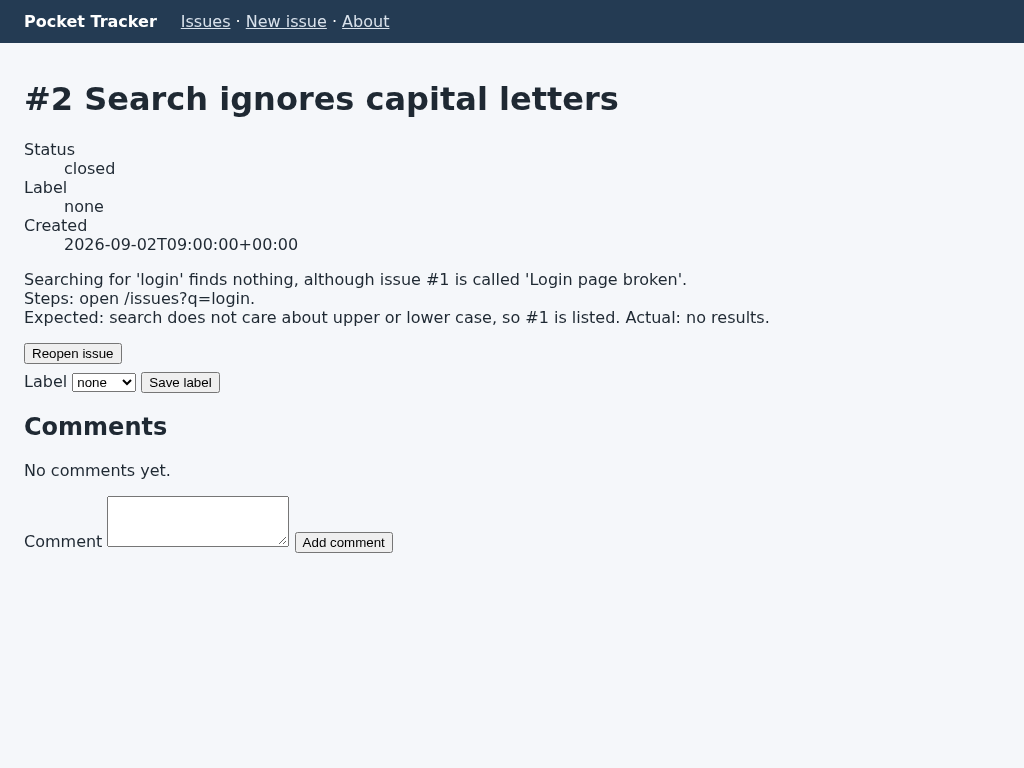

In [24]:
from IPython.display import Image, display
png = EVIDENCE / f"step_{ev:02d}.png" if isinstance(ev, int) else None
png = png if png and png.exists() else (REC_PNG if REC_PNG.exists() else None)
print("showing:", png)
if png:
    display(Image(filename=str(png), width=512))

### 12. Save the recorded run
The model replies are in `llm_replay`'s cassette. This cell saves the browser side (log, steps, evidence snapshots, final rows, replay result) and the cited screenshot. It saves only when the agent loop ran live in this session.

In [25]:
if live_loop:
    REC_PATH.parent.mkdir(parents=True, exist_ok=True)
    REC_PATH.write_text(json.dumps({k: v for k, v in seen.items() if k != "source"}, indent=1, default=str) + "\n")
    if isinstance(ev, int) and (EVIDENCE / f"step_{ev:02d}.png").exists():
        shutil.copy(EVIDENCE / f"step_{ev:02d}.png", REC_PNG)
    print("saved", REC_PATH, "and", REC_PNG.name)
else:
    print("the loop did not run live: keeping the existing recording")

⏭  Skipped: this cell needs [download]. Run it yourself, or re-run with TUT_ENABLE=download.


## At work
- QA and agent teams keep a per-step record (aria snapshot, screenshot, action, result) plus a Playwright trace file, because a non-deterministic run cannot be reproduced from the model alone; the trace format comes in → lesson 54, structured run logs → lesson 44a.
- The usual end product of a browser QA agent is not a transcript but a Playwright test and a filed bug; that pipeline, with bugs filed through MCP, is the next browser checkpoint → lesson 28.
- One reproduced run is one sample. Graders of browser agents check the end state over many runs and report variance → lesson 47.
- Bug reports are untrusted input: a report or page text can carry instructions aimed at the agent ("also delete issue #3") → lesson 49.

## What just happened
- The model read issue #7's report and followed it through the page, one fresh snapshot per step (lesson 12's loop), within 5 calls and 8 actions.
- `observe` saved `step_NN.aria.yaml` and `step_NN.png` on every step, so the evidence existed before the model said anything.
- The `report` tool turned the model's conclusion into data: a claim, its expected and actual results, and the step that shows it.
- The harness checked that claim against the database and against the cited snapshot; both agreed.
- The steps that worked, rewritten by role and name, reproduced the bug on a fresh database with no model, and `report.md` packaged it all.

## Common mistakes
Trusting a verdict that cites any step. Here a hand-written report (not model output) claims reproduction but cites step 0, the issue list, where nothing has happened yet:

In [26]:
bad = {"reproduced": True, "expected": "label stays bug", "actual": "label is empty", "evidence_step": 0}
evidence = run["evidence"] if run else []
assert not check_report(bad, evidence, in_db), check_report(bad, evidence, in_db)

AssertionError: ["step 0's page does not show #2 closed with label none"]

Fix: check that the cited evidence shows the claim, as `check_report` does. Two more:
- Saving refs as repro steps. `f1e19` exists only in the browser that took that snapshot; a fresh browser cannot find it. Save role and name.
- Replaying on a dirty database. After the agent's run #2 is already closed, so a replay proves nothing; restore the fresh copy first.

## Key terms
- **bug reproduction** — following a bug report's steps on the real application and observing the actual result, so the bug is confirmed before anyone fixes it.
- **evidence capture** — the harness saving what the agent saw at every step (here an aria snapshot and a screenshot) to files, so a verdict can be checked and reviewed later.
- **repro steps** — the actions that reproduced a bug, written by role and name instead of refs, so they replay in a fresh browser without a model.

Always run this cell, and run it last: it closes the browser, stops the server and saves the model recording.

In [27]:
if "browser" in globals():
    await browser.close()
    await pw.stop()
server.terminate()
try:
    server.wait(timeout=10)
except subprocess.TimeoutExpired:
    server.kill(); server.wait()
log.close()
print("browser closed, server exit code", server.returncode)
import llm_replay
llm_replay.stop()

browser closed, server exit code -15
